# Inspect selected narration classifier

The official TaskData test set is not used for training, validation, class balancing, threshold selection, early stopping, or architecture decisions. Only labeled development data is used. OCR/GT fields are for supervision and auditing; model input is the padded image crop only. This notebook has not been executed.

Load the saved head and threshold. Evaluate all accepted validation samples without optimization or threshold search. Validation was used for selection, so this is not an independent test estimate.

In [1]:
import random
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoImageProcessor, AutoModel

ROOT = Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/isNarratorText')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
data = torch.load(ROOT / 'narration_data.pt', map_location='cpu', weights_only=True)
assert data['settings']['data_source'] == 'development'
samples = data['samples']
train_sequences = {samples[i]['sequence_id'] for i in data['splits']['train']}
validation_sequences = {samples[i]['sequence_id'] for i in data['splits']['validation']}
assert train_sequences.isdisjoint(validation_sequences)
assert data['splits']['validation'] == [i for i, sample in enumerate(samples)
                                      if sample['sequence_id'] in validation_sequences]
assert set(data['train_sample_indices']) <= set(data['splits']['train'])


In [2]:
checkpoint = torch.load(ROOT / 'narration_linear_head.pt', map_location='cpu', weights_only=True)
assert checkpoint['settings']['bbox_padding'] == data['settings']['bbox_padding']
DINO_PATH = Path(checkpoint['encoder_path'])
processor = AutoImageProcessor.from_pretrained(DINO_PATH, local_files_only=True)
encoder = AutoModel.from_pretrained(DINO_PATH, local_files_only=True)
FEATURE_DIM = encoder.config.hidden_size
assert FEATURE_DIM == checkpoint['feature_dim']


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


In [3]:
class CropDataset(Dataset):
    def __init__(self, indices):
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        sample = samples[self.indices[index]]
        with Image.open(sample['page_path']) as image:
            crop = image.convert('RGB').crop(tuple(sample['padded_bbox']))
        return crop, float(sample['label'])


def collate_crops(batch):
    crops, labels = zip(*batch)
    # Use DINO's own resize and normalization.
    pixels = processor(images=list(crops), return_tensors='pt')['pixel_values']
    return pixels, torch.tensor(labels, dtype=torch.float32)


class NarrationClassifier(nn.Module):
    def __init__(self, encoder, feature_dim):
        super().__init__()
        self.encoder = encoder.requires_grad_(False).eval()
        self.classifier = nn.Linear(feature_dim, 1)

    # Keep DINO in evaluation mode when the head trains.
    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()
        return self

    def forward(self, pixel_values):
        # Extract frozen CLS features without encoder gradients.
        with torch.no_grad():
            features = self.encoder(pixel_values=pixel_values).last_hidden_state[:, 0]
        return self.classifier(features).squeeze(-1)


def metrics_at_threshold(probabilities, labels, threshold):
    predictions = probabilities >= threshold
    positive = labels == 1
    tp = int((predictions & positive).sum())
    fp = int((predictions & ~positive).sum())
    tn = int((~predictions & ~positive).sum())
    fn = int((~predictions & positive).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    negative_recall = tn / max(tn + fp, 1)
    return dict(narration_precision=precision, narration_recall=recall,
                narration_f1=2 * tp / max(2 * tp + fp + fn, 1),
                narration_f0_5=1.25 * tp / max(1.25 * tp + fp + 0.25 * fn, 1),
                not_narration_recall=negative_recall,
                balanced_accuracy=(recall + negative_recall) / 2,
                accuracy=(tp + tn) / max(len(labels), 1), tp=tp, fp=fp, tn=tn, fn=fn)


def evaluate(loader):
    model.eval()
    probabilities, labels_all = [], []
    loss_total = 0.0
    with torch.no_grad():
        for pixels, labels in loader:
            logits = model(pixels.to(DEVICE))
            loss_total += loss_fn(logits, labels.to(DEVICE)).item() * len(labels)
            probabilities.append(logits.sigmoid().cpu())
            labels_all.append(labels)
    return torch.cat(probabilities).numpy(), torch.cat(labels_all).numpy(), loss_total / len(loader.dataset)


In [4]:
model = NarrationClassifier(encoder, FEATURE_DIM).to(DEVICE)
model.classifier.load_state_dict(checkpoint['classifier_state_dict'])
model.eval()
loss_fn = nn.BCEWithLogitsLoss()
validation_loader = DataLoader(CropDataset(data['splits']['validation']), batch_size=16,
    shuffle=False, collate_fn=collate_crops, num_workers=0)
probabilities, labels, validation_loss = evaluate(validation_loader)
# Reuse the selected threshold without tuning it again.
threshold = checkpoint['validation_threshold']
metrics = metrics_at_threshold(probabilities, labels, threshold)
print('Saved threshold:', threshold)
for name in ['narration_precision', 'narration_recall', 'narration_f0_5', 'narration_f1',
             'not_narration_recall', 'balanced_accuracy', 'accuracy']:
    print(f'{name}: {metrics[name]:.4f}')
print(f'Confusion matrix: TN={metrics["tn"]} FP={metrics["fp"]} FN={metrics["fn"]} TP={metrics["tp"]}')


Saved threshold: 0.5716819167137146
narration_precision: 0.4848
narration_recall: 0.8421
narration_f1: 0.6154
not_narration_recall: 0.9489
balanced_accuracy: 0.8955
accuracy: 0.9432
Confusion matrix: TN=316 FP=17 FN=3 TP=16



False positives: 17


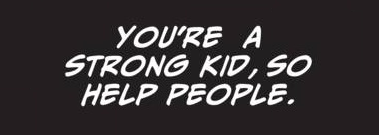

seq_45c9871f52e99417 | page: 1 | text: 0
OCR: You're a strong kid, so help people.
GT text: YOU'RE A STRONG KID, SO HELP PEOPLE.
GT speaker: UNKNOWN
Narration probability: 0.6037


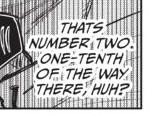

seq_45c9871f52e99417 | page: 2 | text: 2
OCR: thats number two. One-tenth of the way there, huh?
GT text: THAT'S NUMBER TWO. ONE-TENTH OF THE WAY THERE, HUH?
GT speaker: character1
Narration probability: 0.6233


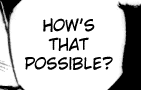

seq_5c5304b3f7796f8c | page: 0 | text: 1
OCR: How's that possible?
GT text: HOW'S THAT POSSIBLE?
GT speaker: character1
Narration probability: 0.6155


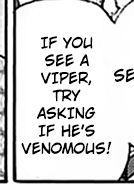

seq_71033fec4de494fc | page: 1 | text: 4
OCR: If you see a viper, try asking if he's venomous!
GT text: IF YOU SEE A VIPER, TRY ASKING IF HE'S VENOMOUS!
GT speaker: character3
Narration probability: 0.6991


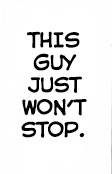

seq_71033fec4de494fc | page: 1 | text: 14
OCR: This guy just won't stop.
GT text: THIS GUY JUST WON'T STOP.
GT speaker: character2
Narration probability: 0.6579

False negatives: 3


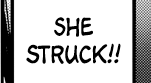

seq_ee880b9612205860 | page: 0 | text: 6
OCR: SHE STRUCK!!
GT text: THIS CRACK DID NOT SLIP PAST SHINOMIYA UNNOTICED!! SHE STRUCK!!
GT speaker: NARRATION
Narration probability: 0.2323


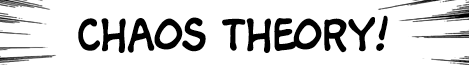

seq_ee880b9612205860 | page: 2 | text: 1
OCR: Chaos theory!
GT text: CHAOS THEORY!
GT speaker: NARRATION
Narration probability: 0.0131


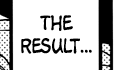

seq_ee880b9612205860 | page: 2 | text: 12
OCR: The result...
GT text: THE RESULT...
GT speaker: NARRATION
Narration probability: 0.2330


In [5]:
from IPython.display import display

predictions = probabilities >= threshold
false_positives = np.flatnonzero(predictions & (labels == 0))
false_negatives = np.flatnonzero(~predictions & (labels == 1))
for title, positions in [('False positives', false_positives), ('False negatives', false_negatives)]:
    print(f'\n{title}: {len(positions)}')
    for position in positions[:5]:
        sample = samples[data['splits']['validation'][int(position)]]
        with Image.open(sample['page_path']) as image:
            display(image.convert('RGB').crop(tuple(sample['padded_bbox'])))
        print(sample['sequence_id'], '| page:', sample['page_idx'], '| text:', sample['text_idx'])
        print('OCR:', sample['ocr_text'])
        print('GT text:', sample['gt_text'])
        print('GT speaker:', sample['gt_speaker'])
        print(f'Narration probability: {probabilities[position]:.4f}')


## Later inference

Use the same padding, local DINO processor, frozen encoder, saved head, and saved threshold. Probability ≥ threshold assigns `NARRATION`; otherwise continue through the normal speaker/character association pipeline. If the baseline is weak, a separate experiment may unfreeze only the final DINO transformer block while keeping dataset, split, sampling, metrics, and threshold logic fixed.